In [1]:
import sys
print(sys.executable)

/home/shubhayu18/Documents/football-analysis/.venv/bin/python


In [9]:
import pandas as pd
from pathlib import Path

csv_path = Path("data/raw/epl_2024_25.csv")

print("CSV exists:", csv_path.exists())

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
df.head()

CSV exists: True
Dataset shape: (380, 120)


,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,B365CAHH,B365CAHA,PCAHH,PCAHA,MaxCAHH,MaxCAHA,AvgCAHH,AvgCAHA,BFECAHH,BFECAHA
0,E0,16/08/2024,20:00,Man United,Fulham,1,0,H,0,0,...,1.86,2.07,1.83,2.11,1.88,2.11,1.82,2.05,1.90,2.08
1,E0,17/08/2024,12:30,Ipswich,Liverpool,0,2,A,0,0,...,2.05,1.88,2.04,1.90,2.20,2.00,1.99,1.88,2.04,1.93
2,E0,17/08/2024,15:00,Arsenal,Wolves,2,0,H,1,0,...,2.02,1.91,2.00,1.90,2.05,1.93,1.99,1.87,2.02,1.96
3,E0,17/08/2024,15:00,Everton,Brighton,0,3,A,0,1,...,1.87,2.06,1.86,2.07,1.92,2.10,1.83,2.04,1.88,2.11
4,E0,17/08/2024,15:00,Newcastle,Southampton,1,0,H,1,0,...,1.87,2.06,1.88,2.06,1.89,2.10,1.82,2.05,1.89,2.10


In [10]:
# 1. Display the first five rows
df.head()
# 2. Find the number of rows and columns
df.shape
# 3. Display all column names
df.columns.tolist()
# 4. Inspect column types and non-null counts
df.info()
# 5. Count missing values in each column
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Columns: 120 entries, Div to BFECAHA
dtypes: float64(96), int64(16), str(8)
memory usage: 356.4 KB


Div         0
Date        0
Time        0
HomeTeam    0
AwayTeam    0
           ..
MaxCAHA     0
AvgCAHH     0
AvgCAHA     0
BFECAHH     0
BFECAHA     0
Length: 120, dtype: int64

In [18]:
print("total missing values: ", df.isnull().sum().sum())

missing = df.isnull().sum()
print("\nmissing columns:\n")
print(missing[missing > 0])

print("duplicate: \n",df.duplicated().sum())

df[
    ["HomeTeam", "AwayTeam", "FTHG", "FTAG", "FTR"]
    ].head(10)

total missing values:  1440

missing columns:

BWH        141
BWD        141
BWA        141
BFH          1
BFD          1
BFA          1
WHH         91
WHD         91
WHA         91
1XBH         9
1XBD         9
1XBA         9
P>2.5        3
P<2.5        3
BFE>2.5      3
BFE<2.5      3
BWCH       141
BWCD       141
BWCA       141
WHCH        91
WHCD        91
WHCA        91
PC>2.5       3
PC<2.5       3
dtype: int64
duplicate: 
 0


,HomeTeam,AwayTeam,FTHG,FTAG,FTR
0,Man United,Fulham,1,0,H
1,Ipswich,Liverpool,0,2,A
2,Arsenal,Wolves,2,0,H
3,Everton,Brighton,0,3,A
4,Newcastle,Southampton,1,0,H
5,Nott'm Forest,Bournemouth,1,1,D
6,West Ham,Aston Villa,1,2,A
7,Brentford,Crystal Palace,2,1,H
8,Chelsea,Man City,0,2,A
9,Leicester,Tottenham,1,1,D


In [21]:
match_columns = [
    "Date",
    "HomeTeam",
    "AwayTeam",
    "FTHG",
    "FTAG",
    "FTR",
    "HS",
    "AS",
    "HST",
    "AST",
]

matches = df[match_columns].copy()

print("original shape: ", df.shape)
print("analysis shape: ", matches.shape)

print("\nMissing values in selected columns:")
print(matches.isnull().sum())

matches.head()

original shape:  (380, 120)
analysis shape:  (380, 10)

Missing values in selected columns:
Date        0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
HS          0
AS          0
HST         0
AST         0
dtype: int64


,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HS,AS,HST,AST
0,16/08/2024,Man United,Fulham,1,0,H,14,10,5,2
1,17/08/2024,Ipswich,Liverpool,0,2,A,7,18,2,5
2,17/08/2024,Arsenal,Wolves,2,0,H,18,9,6,3
3,17/08/2024,Everton,Brighton,0,3,A,9,10,1,5
4,17/08/2024,Newcastle,Southampton,1,0,H,3,19,1,4


In [25]:
matches["TotalGoals"] = matches["FTHG"] + matches["FTAG"]
matches["GoalDifference"] = matches["FTHG"] - matches["FTAG"]

print("\n missing values\n")
print(matches.isnull().sum())

matches[
    ["HomeTeam", "AwayTeam", "FTHG", "FTAG",
     "TotalGoals", "GoalDifference"]
].head(10)


 missing values

Date              0
HomeTeam          0
AwayTeam          0
FTHG              0
FTAG              0
FTR               0
HS                0
AS                0
HST               0
AST               0
TotalGoals        0
GoalDifference    0
dtype: int64


,HomeTeam,AwayTeam,FTHG,FTAG,TotalGoals,GoalDifference
0,Man United,Fulham,1,0,1,1
1,Ipswich,Liverpool,0,2,2,-2
2,Arsenal,Wolves,2,0,2,2
3,Everton,Brighton,0,3,3,-3
4,Newcastle,Southampton,1,0,1,1
5,Nott'm Forest,Bournemouth,1,1,2,0
6,West Ham,Aston Villa,1,2,3,-1
7,Brentford,Crystal Palace,2,1,3,1
8,Chelsea,Man City,0,2,2,-2
9,Leicester,Tottenham,1,1,2,0


In [27]:
print(matches["FTR"].value_counts())

FTR
H    155
A    132
D     93
Name: count, dtype: int64


In [54]:
unique_T = sorted(set(matches["HomeTeam"]))

total_matches_played = {}

for i in range(len(unique_T)):
    cnt1 = 0
    cnt2 = 0
    for j in range(len(matches["HomeTeam"])):
        if unique_T[i] == matches["HomeTeam"].iloc[j]:
            cnt1 += 1
        elif unique_T[i] == matches["AwayTeam"].iloc[j]:
            cnt2 += 1
        else:
            continue
    total_played = cnt1 + cnt2
    total_matches_played[unique_T[i]] = total_played

In [50]:
total_matches_won = {}
total_matches_lost = {}
total_matches_drawn = {}

for i in range(len(unique_T)):
    cnt1 = 0
    cnt2 = 0
    for j in range(len(matches["FTR"])):
        if unique_T[i] == matches["HomeTeam"].iloc[j]:
            if matches["FTR"].iloc[j] == "H":
                cnt1 += 1
        elif unique_T[i] == matches["AwayTeam"].iloc[j]:
            if matches["FTR"].iloc[j] == "A":
                cnt2 += 1
        else:
            continue
    total_won = cnt1 + cnt2
    total_matches_won[unique_T[i]] = total_won

for i in range(len(unique_T)):
    cnt1 = 0
    cnt2 = 0
    for j in range(len(matches["FTR"])):
        if unique_T[i] == matches["HomeTeam"].iloc[j]:
            if matches["FTR"].iloc[j] == "A":
                cnt1 += 1
        elif unique_T[i] == matches["AwayTeam"].iloc[j]:
            if matches["FTR"].iloc[j] == "H":
                cnt2 += 1
        else:
            continue
    total_lost = cnt1 + cnt2
    total_matches_lost[unique_T[i]] = total_lost

for i in range(len(unique_T)):
    cnt1 = 0
    cnt2 = 0
    for j in range(len(matches["FTR"])):
        if unique_T[i] == matches["HomeTeam"].iloc[j]:
            if matches["FTR"].iloc[j] == "D":
                cnt1 += 1
        elif unique_T[i] == matches["AwayTeam"].iloc[j]:
            if matches["FTR"].iloc[j] == "D":
                cnt2 += 1
        else:
            continue
    total_drawn = cnt1 + cnt2
    total_matches_drawn[unique_T[i]] = total_drawn

In [47]:
GF= {} #goals for
GA = {} #goals against

for i in range(len(unique_T)):
    cnt1 = 0
    cnt2 = 0
    for j in range(len(matches["HomeTeam"])):
        if unique_T[i] == matches["HomeTeam"].iloc[j]:
            cnt1 = cnt1 + int(matches["FTHG"].iloc[j])
        elif unique_T[i] == matches["AwayTeam"].iloc[j]:
            cnt2 = cnt2 + int(matches["FTAG"].iloc[j])
        else:
            continue
    total_GF = cnt1 + cnt2
    GF[unique_T[i]] = total_GF
print(GF)
print("\n")

for i in range(len(unique_T)):
    cnt1 = 0
    cnt2 = 0
    for j in range(len(matches["HomeTeam"])):
        if unique_T[i] == matches["HomeTeam"].iloc[j]:
            cnt1 = cnt1 + int(matches["FTAG"].iloc[j])
        elif unique_T[i] == matches["AwayTeam"].iloc[j]:
            cnt2 = cnt2 + int(matches["FTHG"].iloc[j])
        else:
            continue
    total_GA = cnt1 + cnt2
    GA[unique_T[i]] = total_GA
print(GA)

{'Arsenal': 69, 'Aston Villa': 58, 'Bournemouth': 58, 'Brentford': 66, 'Brighton': 66, 'Chelsea': 64, 'Crystal Palace': 51, 'Everton': 42, 'Fulham': 54, 'Ipswich': 36, 'Leicester': 33, 'Liverpool': 86, 'Man City': 72, 'Man United': 44, 'Newcastle': 68, "Nott'm Forest": 58, 'Southampton': 26, 'Tottenham': 64, 'West Ham': 46, 'Wolves': 54}


{'Arsenal': 34, 'Aston Villa': 51, 'Bournemouth': 46, 'Brentford': 57, 'Brighton': 59, 'Chelsea': 43, 'Crystal Palace': 51, 'Everton': 44, 'Fulham': 54, 'Ipswich': 82, 'Leicester': 80, 'Liverpool': 41, 'Man City': 44, 'Man United': 54, 'Newcastle': 47, "Nott'm Forest": 46, 'Southampton': 86, 'Tottenham': 65, 'West Ham': 62, 'Wolves': 69}


In [49]:
goal_difference = {}

for i in range(len(unique_T)):
    goal_difference[unique_T[i]] = GF[unique_T[i]] - GA[unique_T[i]]

print(goal_difference)


{'Arsenal': 35, 'Aston Villa': 7, 'Bournemouth': 12, 'Brentford': 9, 'Brighton': 7, 'Chelsea': 21, 'Crystal Palace': 0, 'Everton': -2, 'Fulham': 0, 'Ipswich': -46, 'Leicester': -47, 'Liverpool': 45, 'Man City': 28, 'Man United': -10, 'Newcastle': 21, "Nott'm Forest": 12, 'Southampton': -60, 'Tottenham': -1, 'West Ham': -16, 'Wolves': -15}


In [52]:
total_points = {}

for i in range(len(unique_T)):
    total_points[unique_T[i]] = (3*total_matches_won[unique_T[i]]) + (total_matches_drawn[unique_T[i]])

print(total_points)

{'Arsenal': 74, 'Aston Villa': 66, 'Bournemouth': 56, 'Brentford': 56, 'Brighton': 61, 'Chelsea': 69, 'Crystal Palace': 53, 'Everton': 48, 'Fulham': 54, 'Ipswich': 22, 'Leicester': 25, 'Liverpool': 84, 'Man City': 71, 'Man United': 42, 'Newcastle': 66, "Nott'm Forest": 65, 'Southampton': 12, 'Tottenham': 38, 'West Ham': 43, 'Wolves': 42}


In [59]:
league_table = pd.DataFrame({
    "Played": total_matches_played,
    "Wins": total_matches_won,
    "Draws": total_matches_drawn,
    "Losses": total_matches_lost,
    "GF": GF,
    "GA": GA,
    "GD": goal_difference,
    "Points": total_points
})

league_table = league_table.sort_values(
    by=["Points", "GD", "GF"],
    ascending=[False, False, False]
)

display(league_table)



,Played,Wins,Draws,Losses,GF,GA,GD,Points
Liverpool,38,25,9,4,86,41,45,84
Arsenal,38,20,14,4,69,34,35,74
Man City,38,21,8,9,72,44,28,71
Chelsea,38,20,9,9,64,43,21,69
Newcastle,38,20,6,12,68,47,21,66
Aston Villa,38,19,9,10,58,51,7,66
Nott'm Forest,38,19,8,11,58,46,12,65
Brighton,38,16,13,9,66,59,7,61
Bournemouth,38,15,11,12,58,46,12,56
Brentford,38,16,8,14,66,57,9,56


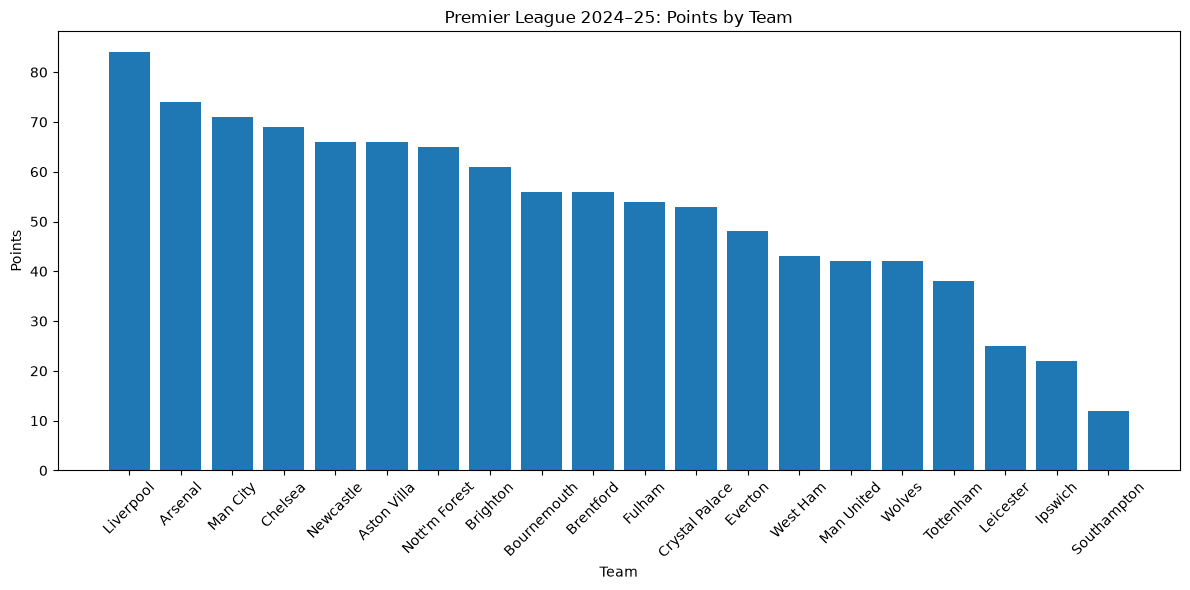

In [132]:
import matplotlib.pyplot as plt

plt.figure(figsize = (12,6))

plt.bar(league_table.index, league_table["Points"])

plt.title("Premier League 2024–25: Points by Team")
plt.xlabel("Team")
plt.ylabel("Points")

plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    "outputs/figures/league_points.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

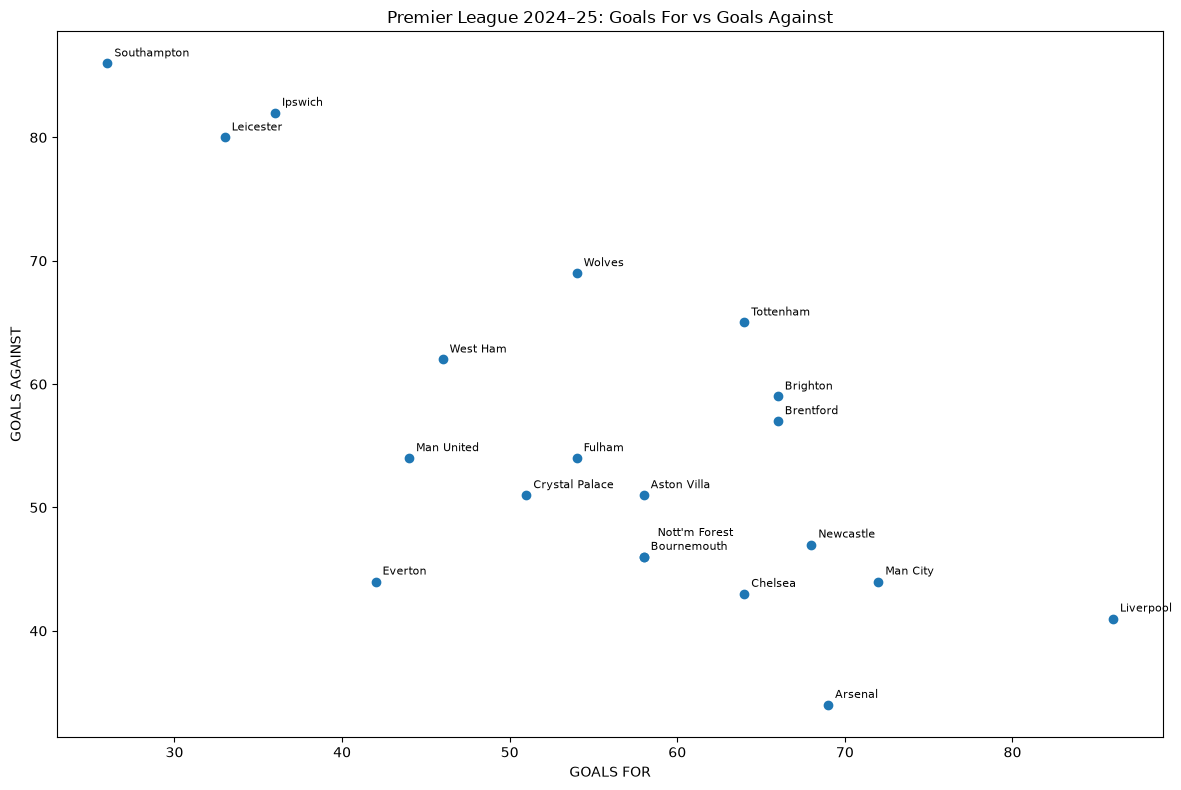

In [133]:
plt.figure(figsize = (12,8))

plt.scatter(league_table["GF"], league_table["GA"])
for team, row in league_table.iterrows():
    offset = (5, 5)

    if team == "Nott'm Forest":
        offset = (10, 15)

    plt.annotate(
        team,
        (row["GF"], row["GA"]),
        xytext=offset,
        textcoords="offset points",
        fontsize=8
)

plt.title("Premier League 2024–25: Goals For vs Goals Against")
plt.xlabel("GOALS FOR")
plt.ylabel("GOALS AGAINST")

plt.tight_layout()
plt.savefig(
    "outputs/figures/goals_for_vs_goals_against.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [95]:
home_wins = {}
away_wins = {}
home_goals = {}
away_goals = {}

for i in range(len(unique_T)):
    cnt1 = 0
    cnt2 = 0
    for j in range(len(matches["FTR"])):
        if unique_T[i] == matches["HomeTeam"].iloc[j]:
            if matches["FTR"].iloc[j] == "H":
                cnt1 += 1
        elif unique_T[i] == matches["AwayTeam"].iloc[j]:
            if matches["FTR"].iloc[j] == "A":
                cnt2 += 1
        else:
            continue
    home_wins[unique_T[i]] = cnt1
    away_wins[unique_T[i]] = cnt2

for i in range(len(unique_T)):
    cnt1 = 0
    cnt2 = 0
    for j in range(len(matches["HomeTeam"])):
        if unique_T[i] == matches["HomeTeam"].iloc[j]:
            cnt1 = cnt1 + int(matches["FTHG"].iloc[j])
        elif unique_T[i] == matches["AwayTeam"].iloc[j]:
            cnt2 = cnt2 + int(matches["FTAG"].iloc[j])
        else:
            continue
    home_goals[unique_T[i]] = cnt1
    away_goals[unique_T[i]] = cnt2

In [96]:
league_table["HomeWins"] = home_wins
league_table["AwayWins"] = away_wins
league_table["HomeGoals"] = home_goals
league_table["AwayGoals"] = away_goals

In [97]:
display(league_table)

,Played,Wins,Draws,Losses,GF,GA,GD,Points,HomeWins,AwayWins,HomeGoals,AwayGoals
Liverpool,38,25,9,4,86,41,45,84,14,11,42,44
Arsenal,38,20,14,4,69,34,35,74,11,9,35,34
Man City,38,21,8,9,72,44,28,71,13,8,43,29
Chelsea,38,20,9,9,64,43,21,69,12,8,35,29
Newcastle,38,20,6,12,68,47,21,66,12,8,40,28
Aston Villa,38,19,9,10,58,51,7,66,11,8,34,24
Nott'm Forest,38,19,8,11,58,46,12,65,9,10,26,32
Brighton,38,16,13,9,66,59,7,61,8,8,30,36
Bournemouth,38,15,11,12,58,46,12,56,8,7,23,35
Brentford,38,16,8,14,66,57,9,56,9,7,40,26


In [98]:
league_table["HomeWinDiff"] = league_table["HomeWins"] - league_table["AwayWins"]
league_table["HomeAwayGoalDiff"] = league_table["HomeGoals"] - league_table["AwayGoals"]

In [99]:
display(league_table)


,Played,Wins,Draws,Losses,GF,GA,GD,Points,HomeWins,AwayWins,HomeGoals,AwayGoals,HomeWinDiff,HomeAwayGoalDiff
Liverpool,38,25,9,4,86,41,45,84,14,11,42,44,3,-2
Arsenal,38,20,14,4,69,34,35,74,11,9,35,34,2,1
Man City,38,21,8,9,72,44,28,71,13,8,43,29,5,14
Chelsea,38,20,9,9,64,43,21,69,12,8,35,29,4,6
Newcastle,38,20,6,12,68,47,21,66,12,8,40,28,4,12
Aston Villa,38,19,9,10,58,51,7,66,11,8,34,24,3,10
Nott'm Forest,38,19,8,11,58,46,12,65,9,10,26,32,-1,-6
Brighton,38,16,13,9,66,59,7,61,8,8,30,36,0,-6
Bournemouth,38,15,11,12,58,46,12,56,8,7,23,35,1,-12
Brentford,38,16,8,14,66,57,9,56,9,7,40,26,2,14


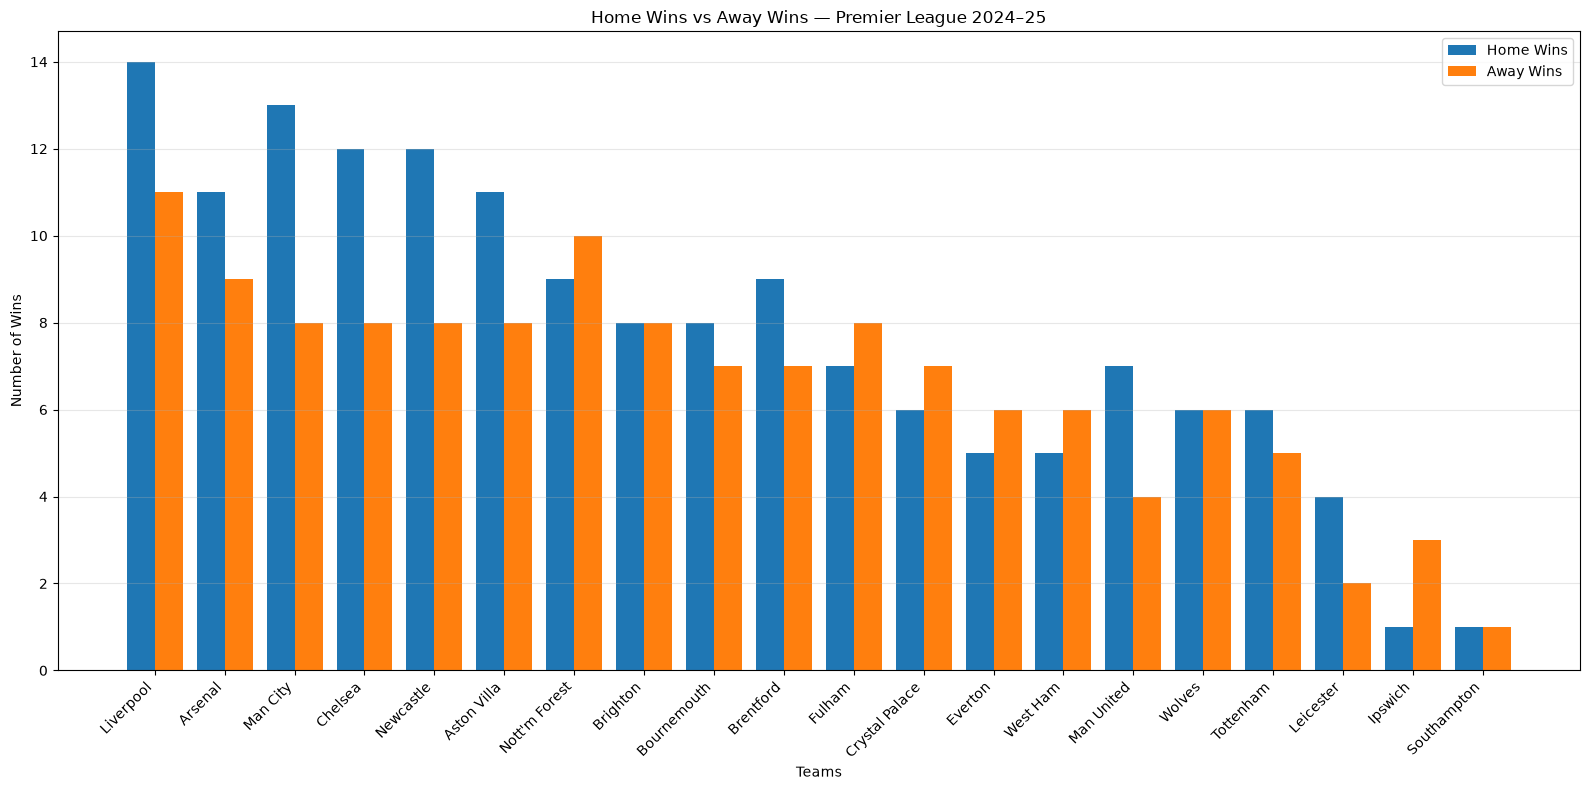

In [134]:
import numpy as np


x = np.arange(len(league_table))
width = 0.4

plt.figure(figsize=(16, 8))

plt.bar(x - width/2, league_table["HomeWins"], width, label="Home Wins")
plt.bar(x + width/2, league_table["AwayWins"], width, label="Away Wins")

plt.xlabel("Teams")
plt.ylabel("Number of Wins")
plt.title("Home Wins vs Away Wins — Premier League 2024–25")

plt.xticks(x, league_table.index, rotation=45, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    "outputs/figures/home_wins_vs_away_wins.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

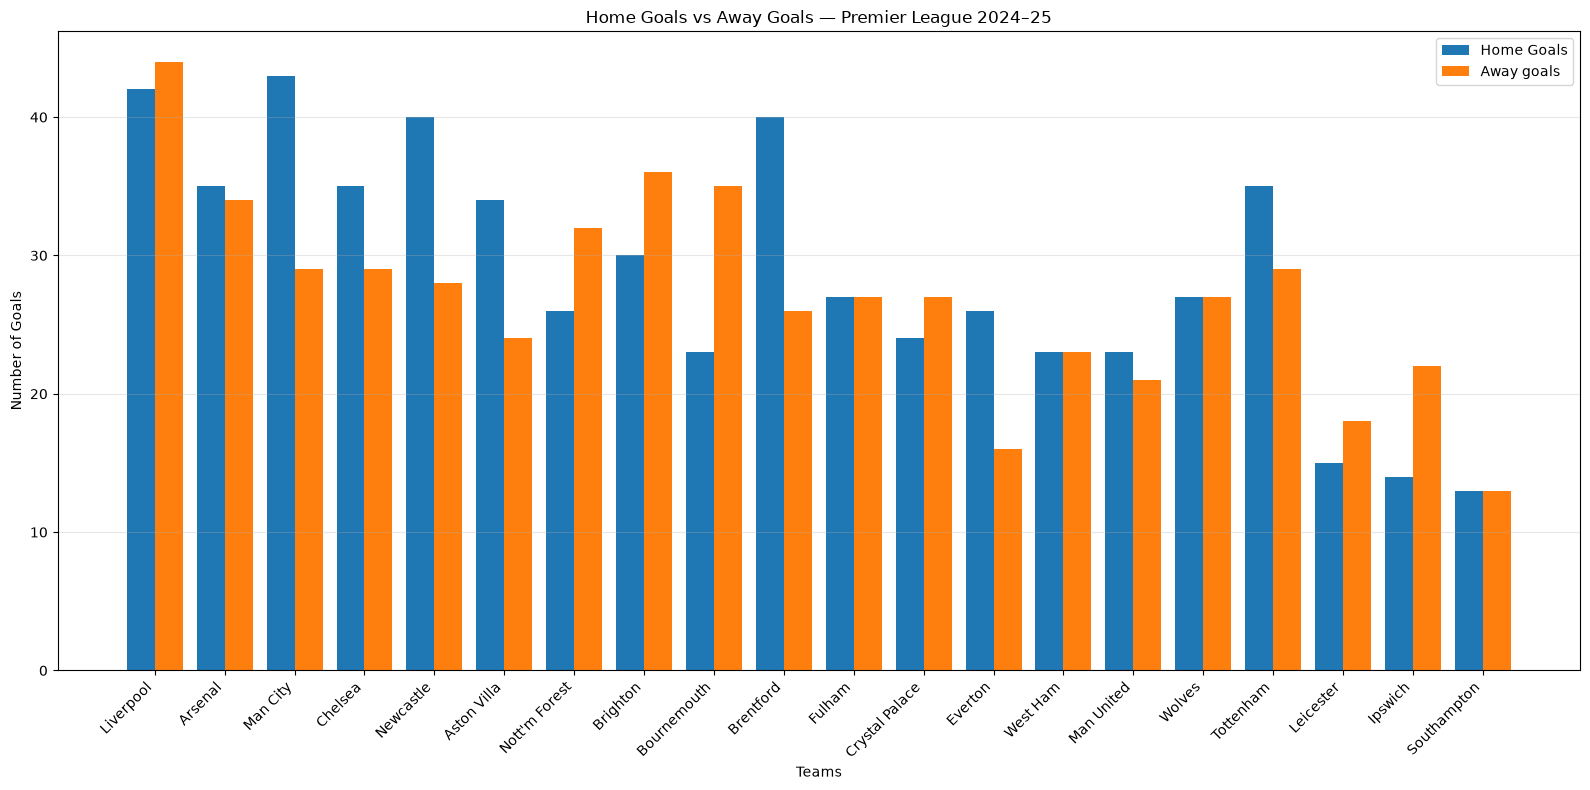

In [135]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(league_table))
width = 0.4

plt.figure(figsize=(16, 8))

plt.bar(x - width/2, league_table["HomeGoals"], width, label="Home Goals")
plt.bar(x + width/2, league_table["AwayGoals"], width, label="Away goals")

plt.xlabel("Teams")
plt.ylabel("Number of Goals")
plt.title("Home Goals vs Away Goals — Premier League 2024–25")

plt.xticks(x, league_table.index, rotation=45, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(
    "outputs/figures/home_goals_vs_away_goals.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [106]:
home_goal_percentage = {}

for i in range(len(unique_T)):
    cnt1 = 0
    cnt2 = 0
    for j in range(len(matches["HomeTeam"])):
        if unique_T[i] == matches["HomeTeam"].iloc[j]:
            cnt1 = cnt1 + int(matches["FTHG"].iloc[j])
        elif unique_T[i] == matches["AwayTeam"].iloc[j]:
            cnt2 = cnt2 + int(matches["FTAG"].iloc[j])
        else:
            continue
    home_goal_percentage[unique_T[i]] = 100*(cnt1/(cnt1 + cnt2))

home_goal_percentage = {
    team: round(ratio, 2)
    for team, ratio in home_goal_percentage.items()
}

print(home_goal_percentage)

{'Arsenal': 50.72, 'Aston Villa': 58.62, 'Bournemouth': 39.66, 'Brentford': 60.61, 'Brighton': 45.45, 'Chelsea': 54.69, 'Crystal Palace': 47.06, 'Everton': 61.9, 'Fulham': 50.0, 'Ipswich': 38.89, 'Leicester': 45.45, 'Liverpool': 48.84, 'Man City': 59.72, 'Man United': 52.27, 'Newcastle': 58.82, "Nott'm Forest": 44.83, 'Southampton': 50.0, 'Tottenham': 54.69, 'West Ham': 50.0, 'Wolves': 50.0}


In [111]:
total_home_goals = 0
total_away_goals = 0
for i in range(len(league_table["HomeGoals"])):
    total_home_goals = total_home_goals + league_table["HomeGoals"].iloc[i]
    total_away_goals = total_away_goals + league_table["AwayGoals"].iloc[i]

league_home_goal_percentage = 100*(total_home_goals/(total_home_goals + total_away_goals))
league_home_goal_percentage = round(league_home_goal_percentage,2)
    

print(league_home_goal_percentage)

    

51.57


In [126]:
league_result_summary = {}
total_matches = len(matches)

total_home_wins = 0
total_away_wins = 0
total_draws = 0

for i in range(len(league_table["HomeGoals"])):
    total_home_wins = total_home_wins + league_table["HomeWins"].iloc[i]
    total_away_wins = total_away_wins + league_table["AwayWins"].iloc[i]

total_draws = (matches["FTR"] == "D").sum()

home_win_per = round(100 * (total_home_wins / total_matches), 2)
away_win_per = round(100 * (total_away_wins / total_matches), 2)
draw_per = round(100 * (total_draws / total_matches), 2)

league_result_summary["Home_Wins"] = int(total_home_wins)
league_result_summary["Away_Wins"] = int(total_away_wins)
league_result_summary["Draws"] = int(total_draws)

league_result_summary["HomeWinPct"] = float(home_win_per)
league_result_summary["AwayWinPct"] = float(away_win_per)
league_result_summary["DrawPct"] = float(draw_per)

print(league_result_summary)

{'Home_Wins': 155, 'Away_Wins': 132, 'Draws': 93, 'HomeWinPct': 40.79, 'AwayWinPct': 34.74, 'DrawPct': 24.47}


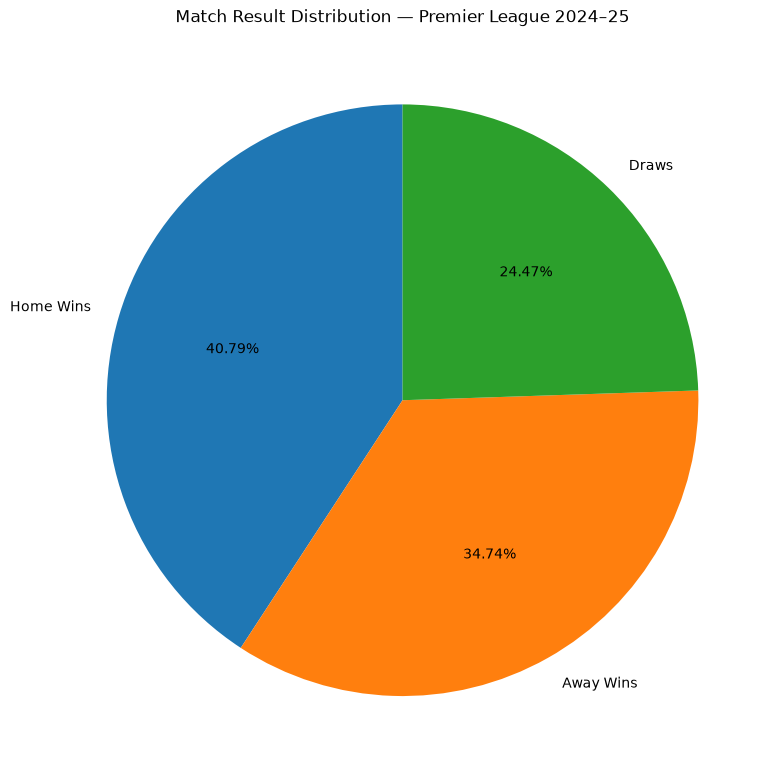

In [136]:
labels = ["Home Wins", "Away Wins", "Draws"]

values = [
    league_result_summary["Home_Wins"],
    league_result_summary["Away_Wins"],
    league_result_summary["Draws"]
]

plt.figure(figsize=(8, 8))

plt.pie(
    values,
    labels=labels,
    autopct="%1.2f%%",
    startangle=90
)

plt.title("Match Result Distribution — Premier League 2024–25")
plt.tight_layout()
plt.savefig(
    "outputs/figures/match_result_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

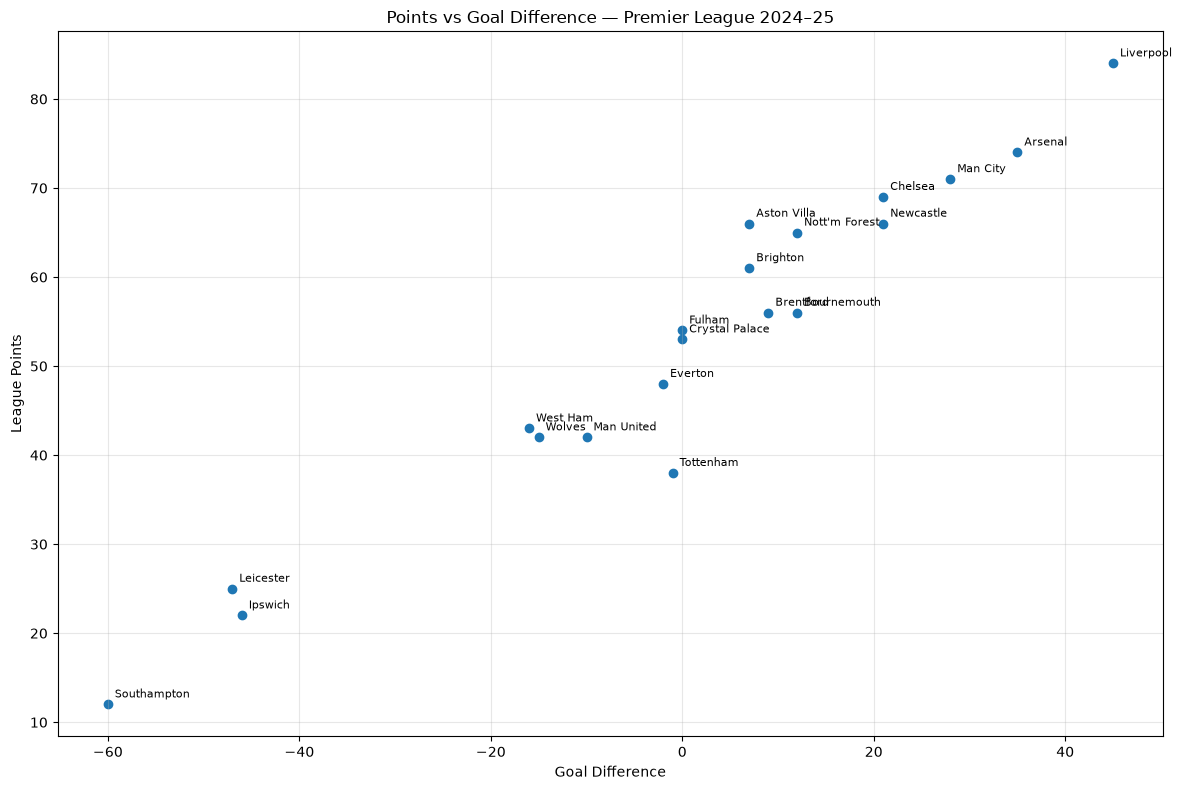

In [137]:
plt.figure(figsize=(12, 8))

plt.scatter(league_table["GD"], league_table["Points"])

for team, row in league_table.iterrows():
    plt.annotate(
        team,
        (row["GD"], row["Points"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.xlabel("Goal Difference")
plt.ylabel("League Points")
plt.title("Points vs Goal Difference — Premier League 2024–25")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "outputs/figures/points_vs_goal_difference.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

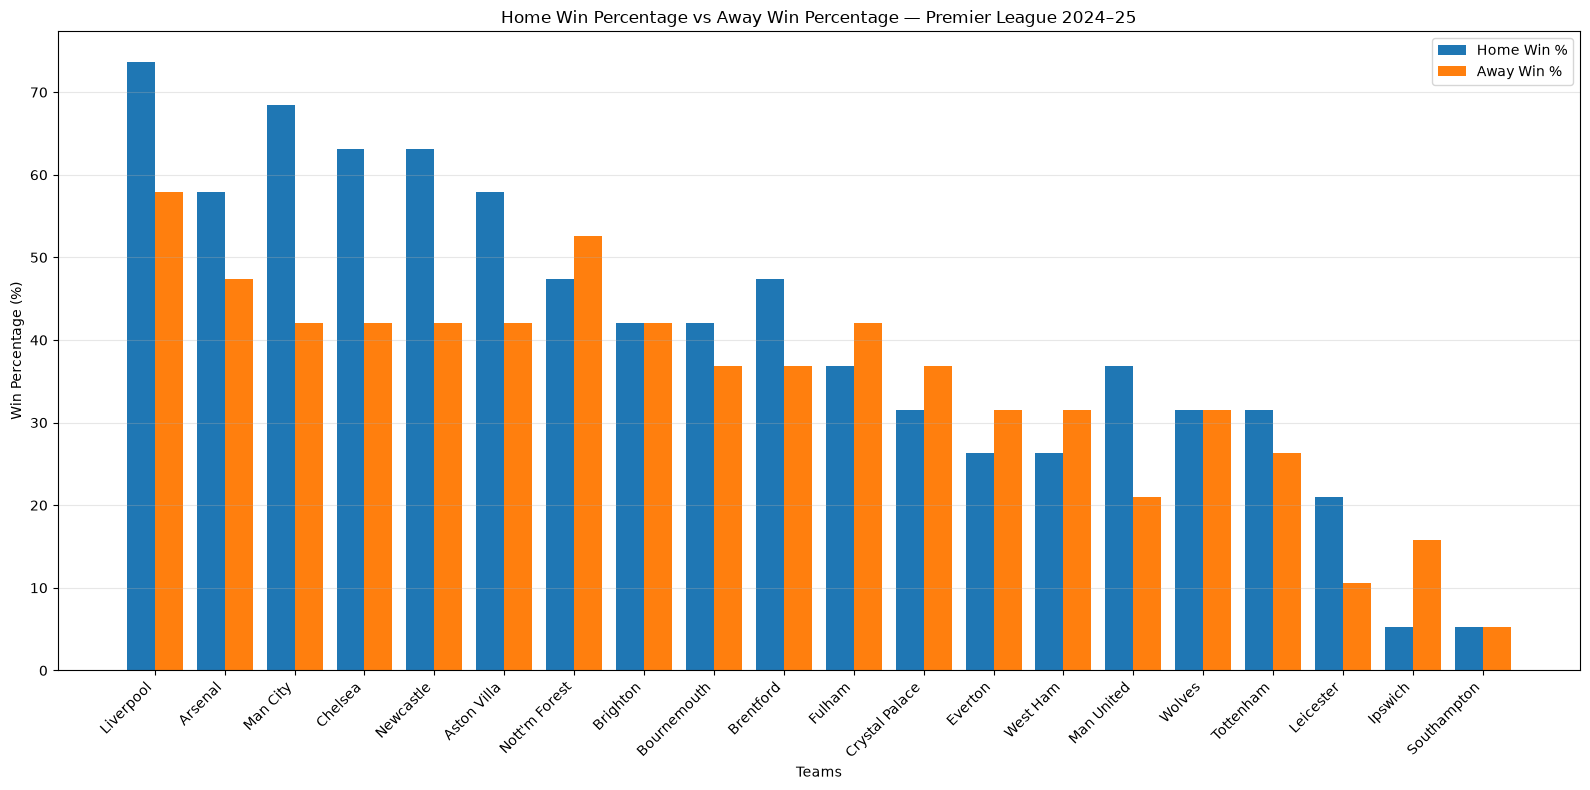

In [138]:
import numpy as np
import matplotlib.pyplot as plt

x = np.arange(len(league_table))
width = 0.4

home_win_pct = (league_table["HomeWins"] / 19) * 100
away_win_pct = (league_table["AwayWins"] / 19) * 100

plt.figure(figsize=(16, 8))

plt.bar(x - width/2, home_win_pct, width, label="Home Win %")
plt.bar(x + width/2, away_win_pct, width, label="Away Win %")

plt.xlabel("Teams")
plt.ylabel("Win Percentage (%)")
plt.title("Home Win Percentage vs Away Win Percentage — Premier League 2024–25")

plt.xticks(x, league_table.index, rotation=45, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "outputs/figures/home_vs_away_win_percentage.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [131]:
league_table.to_csv(
    "outputs/tables/league_table_2024_25.csv",
    index=True
)

In [139]:

import pandas as pd

from football_analysis.cleaning import prepare_matches
from football_analysis.metrics import (
    calculate_league_table,
    calculate_result_summary,
)
from football_analysis.visualization import (
    plot_league_points,
    plot_goals_scatter,
    plot_home_away_win_percentage,
)

df = pd.read_csv("data/raw/epl_2024_25.csv")

matches = prepare_matches(df)

league_table = calculate_league_table(matches)
league_result_summary = calculate_result_summary(matches)

league_table.to_csv("outputs/tables/league_table_2024_25.csv")

plot_league_points(league_table)
plot_goals_scatter(league_table)
plot_home_away_win_percentage(league_table)

print(league_result_summary)


ModuleNotFoundError: No module named 'football_analysis'

In [140]:
import sys
from pathlib import Path

project_root = Path.cwd()

if not (project_root / "src" / "football_analysis").is_dir():
    raise FileNotFoundError(
        "Run Jupyter from the football-analysis project root."
    )

sys.path.insert(0, str(project_root / "src"))

In [141]:
import pandas as pd

from football_analysis.cleaning import prepare_matches
from football_analysis.metrics import (
    calculate_league_table,
    calculate_result_summary,
)
from football_analysis.visualization import (
    plot_league_points,
    plot_goals_scatter,
    plot_home_away_win_percentage,
)